# Prepare the Data

In [1]:
# Imports
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from sklearn.metrics import precision_recall_curve
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

In [2]:
train_set = pd.read_parquet("train_set.parquet")
test_set = pd.read_parquet("test_set.parquet")

In [3]:
# Split into features and labels
X_train = train_set.drop(columns="early_spring").astype(float)
y_train = train_set["early_spring"].astype(bool)

X_train.shape, y_train.mean()

((57, 21), np.float64(0.19298245614035087))

In [4]:
# Look at the features: how many are missing, and what do they look like?
print("Missing values per column (only those with some):")
missing = X_train.isna().sum()
print(missing[missing > 0])

X_train.describe().T.round(2)

Missing values per column (only those with some):
cold_days         1
air_feb_late      1
air_feb           1
oni_son           4
oni_ond           4
oni_ndj           4
oni_trend         4
ao_nov            4
ao_dec            4
ao_jan            3
ao_winter_mean    4
dtype: int64


,count,mean,std,min,25%,50%,75%,max
year,57.0,1977.86,18.75,1947.00,1962.00,1977.00,1994.00,2010.00
phil_early,57.0,0.16,0.37,0.00,0.00,0.00,0.00,1.00
snow_days,57.0,13.37,8.41,0.00,6.00,14.00,18.00,29.00
cold_days,56.0,12.36,4.82,2.00,9.00,11.00,16.00,25.00
gdd,57.0,45.35,35.19,0.50,22.00,37.00,62.50,138.00
air_feb_late,56.0,32.14,6.25,15.36,28.14,31.74,37.64,44.30
soil_feb_late,57.0,0.24,1.37,-3.95,-0.56,-0.01,0.88,4.38
soil_moisture,57.0,0.47,0.01,0.45,0.47,0.47,0.48,0.49
air_feb,56.0,29.81,4.57,17.07,27.54,29.46,33.05,38.38
soil_feb,57.0,-0.09,1.03,-2.89,-0.78,-0.00,0.46,2.36


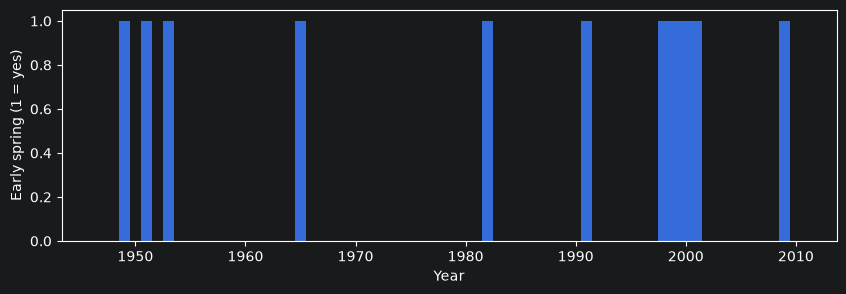

year
1940    0.33
1950    0.22
1960    0.11
1970    0.00
1980    0.10
1990    0.43
2000    0.33
2010    0.00
Name: early_spring, dtype: float64

In [5]:
# Look at the labels over time: the early spring rate has been climbing
plt.figure(figsize=(10, 3))
plt.bar(train_set.year, y_train, width=1.0)
plt.xlabel("Year")
plt.ylabel("Early spring (1 = yes)")
plt.show()

# Early spring rate by decade
y_train.groupby(train_set.year // 10 * 10).mean().round(2)

The early spring rate has been increasing over the years, which may indicate a trend related to climate change or other environmental factors. The bar chart shows the distribution of early spring occurrences over time, while the grouped mean by decade provides a clearer view of how the rate has changed across different periods. This information is essential for understanding the context of the data and for building predictive models that account for temporal trends.

In [6]:
SEED_COST = 0.2   # fraction of the extra harvest's revenue (client)

def profit_per_year(y_true, buy):
    # Average profit per year if we buy seeds whenever buy == True
    y_true, buy = np.asarray(y_true, dtype=bool), np.asarray(buy, dtype=bool)
    return np.mean(buy * (y_true * (1 - SEED_COST) - ~y_true * SEED_COST))

Seeds cost 20% of the extra harvest's revenue. A correct purchase gains 0.8, a wasted purchase loses 0.2, and not buying is 0. So we make money whenever more than 1 in 5 purchases pays off. Accuracy ignores this, so we also compute the profit per year of every set of predictions.

In [7]:
# The naive strategies to beat: never buy and always buy
print("Never buy: ", profit_per_year(y_train, np.zeros(len(y_train))))
print("Always buy:", profit_per_year(y_train, np.ones(len(y_train))))

Never buy:  0.0
Always buy: -0.0070175438596491125


In [8]:
# the training part of every cross-validation fold, so nothing leaks from the validation fold.
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regressor", LogisticRegression(random_state=42, max_iter=1000))
])
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_train)
y_pred[:15], y_train[:15].array

(array([False, False,  True, False, False, False,  True, False, False,
         True, False, False, False, False, False]),
 <NumpyExtensionArray>
 [False, False,  True, False,  True, False,  True, False, False, False, False,
  False, False, False, False]
 Length: 15, dtype: bool)

In [9]:
# Accuracy on the data it was trained on
(y_pred == y_train).mean()

np.float64(0.8596491228070176)

In [10]:
# Use cross validation with 5 folds and using accuracy scoring
# NOTE: we only have ~60 years, so these scores are noisy - look at the spread, not just the mean
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="accuracy")
scores, scores.mean()

(array([0.41666667, 0.75      , 0.81818182, 0.90909091, 0.72727273]),
 np.float64(0.7242424242424242))

In [11]:
# Use cross validation to get the prediction and then use those to calculate the confusion matrix
y_train_pred = cross_val_predict(pipeline, X_train, y_train, cv=cv)
cm = confusion_matrix(y_train, y_train_pred)
cm

array([[39,  7],
       [ 9,  2]])

To determine how well the model is performing, we can analyze the confusion matrix, which shows the counts of true positives, false positives, true negatives, and false negatives. The confusion matrix provides insight into the model's ability to correctly predict early spring occurrences and helps identify areas for improvement.

| | Model said buy | Model said don’t buy |
| :--- | :--- | :--- |
| **Early spring happened** | **True Positive (TP):** bought, and it paid off | **False Negative (FN):** didn’t buy, missed the extra harvest |
| **Early spring didn’t happen** | **False Positive (FP):** bought, seeds wasted | **True Negative (TN):** didn’t buy, correctly saved the money |

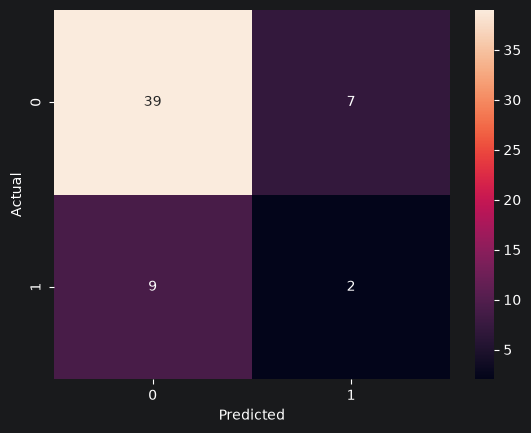

In [12]:
# View the confusion matrix with Seaborn
sns.heatmap(cm, annot=True, fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [13]:
# Break up the confusion matrix into its 4 values
(TN,FP),(FN,TP) = cm

# Compute accuracy, precision, and recall
accuracy  = (TP+TN)/(TP+TN+FP+FN)
precision = TP/(TP+FP)          # of the years we bought, how many were really early
recall    = TP/(TP+FN)          # of the early springs, how many did we catch
f1 = 2 * (precision * recall) / (precision + recall)

accuracy, precision, recall, f1

(np.float64(0.7192982456140351),
 np.float64(0.2222222222222222),
 np.float64(0.18181818181818182),
 np.float64(0.19999999999999998))

In [14]:
# Calculate basic metrics
accuracy  = accuracy_score (y_train, y_train_pred) # (TP+TN)/(TN+TP+FN+FP)
precision = precision_score(y_train, y_train_pred) # TP/(TP+FP)
recall    = recall_score   (y_train, y_train_pred) # TP/(TP+FN)
f1 = f1_score(y_train, y_train_pred) # 2*precision*recall/(precision+recall)
accuracy, precision, recall, f1

(0.7192982456140351, 0.2222222222222222, 0.18181818181818182, 0.2)

In [15]:
# What is the profit if we follow these predictions?
profit_per_year(y_train, y_train_pred)

np.float64(0.0035087719298245615)

In [16]:
# Get the probability of an early spring for each year (out-of-fold, so the model never saw that year)
y_scores = cross_val_predict(pipeline, X_train, y_train, cv=cv, method="predict_proba")[:,1]
y_scores[:10].round(2)

array([0.01, 0.03, 0.38, 0.03, 0.28, 0.2 , 0.57, 0.04, 0.09, 0.98])

In [17]:
# Show the effect of changing the threshold on the precision/recall/profit tradeoff
# NOTE: break-even is 0.2, since we only need to be right 1 time out of 5 to not lose money
print("Threshold Precision Recall    F1 Score  Profit/yr")
for thresh in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    buy = y_scores > thresh
    prec = precision_score(y_train, buy, zero_division=0)
    recall = recall_score(y_train, buy)
    f1 = f1_score(y_train, buy, zero_division=0)
    print(f"{thresh:9.1f} {prec:.7f} {recall:.7f} {f1:.7f} {profit_per_year(y_train, buy):9.3f}")

Threshold Precision Recall    F1 Score  Profit/yr
      0.1 0.2580645 0.7272727 0.3809524     0.032
      0.2 0.1904762 0.3636364 0.2500000    -0.004
      0.3 0.1875000 0.2727273 0.2222222    -0.004
      0.4 0.1428571 0.1818182 0.1600000    -0.014
      0.5 0.2222222 0.1818182 0.2000000     0.004
      0.6 0.1428571 0.0909091 0.1111111    -0.007


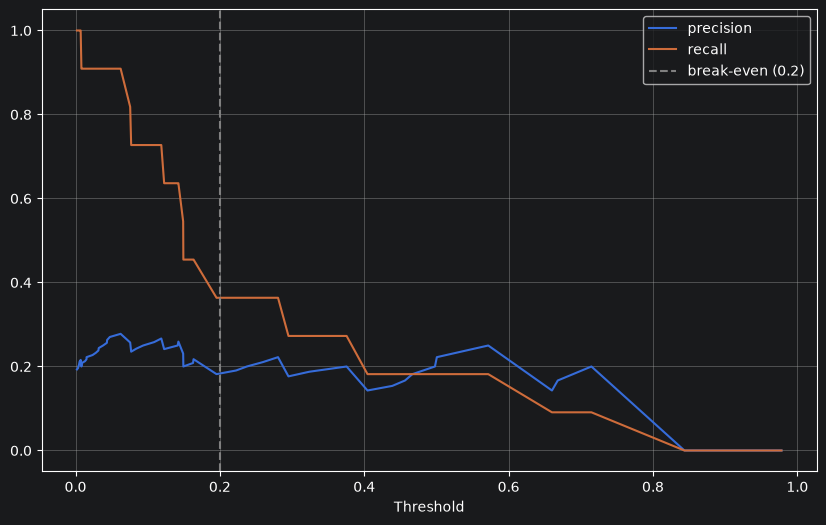

In [18]:
# Get the precision and recall graphs
plt.figure(figsize=(10, 6))
precs, recalls, thresh = precision_recall_curve(y_train, y_scores)
plt.plot(thresh, precs[:-1], label="precision")
plt.plot(thresh, recalls[:-1], label="recall")
plt.axvline(SEED_COST, color="gray", linestyle="--", label="break-even (0.2)")
plt.grid()
plt.xlabel("Threshold")
plt.legend()
plt.show()

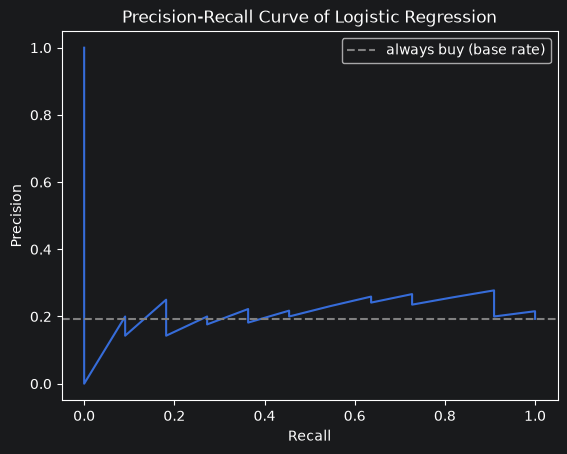

In [19]:
# Plot them against each other - the precision-recall curve
plt.plot(recalls, precs)
plt.axhline(y_train.mean(), color="gray", linestyle="--", label="always buy (base rate)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve of Logistic Regression")
plt.legend()
plt.show()

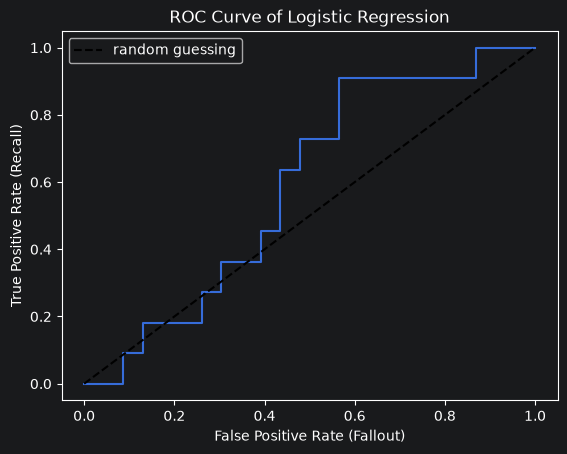

In [20]:
# Plot ROC curve
fpr, tpr, threshs = roc_curve(y_train, y_scores)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], "k--", label="random guessing")
plt.xlabel("False Positive Rate (Fallout)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve of Logistic Regression")
plt.legend()
plt.show()

In [21]:
from sklearn.metrics import roc_auc_score

# Calculate the ROC Area Under the Curve
auc = roc_auc_score(y_train, y_scores)
auc

0.5889328063241106

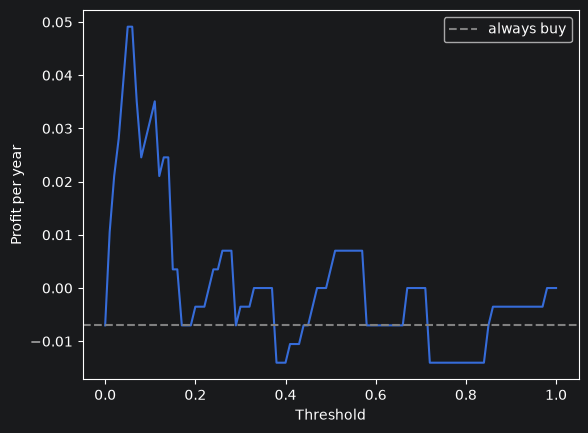

(np.float64(0.05), np.float64(0.04912280701754386))

In [22]:
# Profit per year at every threshold - the best one is the buy / don't-buy cutoff to use
thresholds = np.linspace(0, 1, 101)
profits = [profit_per_year(y_train, y_scores > t) for t in thresholds]

plt.plot(thresholds, profits)
plt.axhline(profit_per_year(y_train, np.ones(len(y_train))), color="gray", linestyle="--", label="always buy")
plt.xlabel("Threshold")
plt.ylabel("Profit per year")
plt.legend()
plt.show()

thresholds[np.argmax(profits)], max(profits)

In [23]:
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier

# The models to try. Each one gets the same imputing and scaling in front of it.
models = {
    "Dummy (base rate)":   DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Logistic Reg (C=0.1)": LogisticRegression(C=0.1, max_iter=1000),   # stronger regularization
    "KNN":                 KNeighborsClassifier(n_neighbors=7),
    "SVM (RBF)":           SVC(probability=True, random_state=42),
    "Naive Bayes":         GaussianNB(),
    "Random Forest":       RandomForestClassifier(n_estimators=200, min_samples_leaf=3, random_state=42),
    "Gradient Boosting":   GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=42),
}
pipelines = {name: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), m) for name, m in models.items()}

In [25]:
# Compute the out-of-fold probabilities for every model
all_scores = {}
for name, pipe in pipelines.items():
    all_scores[name] = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:,1]

/Users/maelt/Courses Fall 2026/Machine Learning /P1-Early-Spring-Ultron/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/maelt/Courses Fall 2026/Machine Learning /P1-Early-Spring-Ultron/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/maelt/Courses Fall 2026/Machine Learning /P1-Early-Spring-Ultron/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`


In [26]:
# Compute the scores for all models using the break-even threshold of 0.2 (buy if there is more than a 20% chance)
rows = []
for name, scores in all_scores.items():
    buy = scores > SEED_COST
    rows.append({"model": name,
                 "accuracy":  accuracy_score(y_train, buy),
                 "precision": precision_score(y_train, buy, zero_division=0),
                 "recall":    recall_score(y_train, buy),
                 "f1":        f1_score(y_train, buy, zero_division=0),
                 "roc_auc":   roc_auc_score(y_train, scores),
                 "profit/yr": profit_per_year(y_train, buy)})
results = pd.DataFrame(rows).set_index("model").round(3)
results.sort_values("profit/yr", ascending=False)

,accuracy,precision,recall,f1,roc_auc,profit/yr
model,,,,,,
Random Forest,0.702,0.364,0.727,0.485,0.674,0.063
Gradient Boosting,0.737,0.357,0.455,0.400,0.532,0.039
Naive Bayes,0.649,0.286,0.545,0.375,0.510,0.032
Logistic Reg (C=0.1),0.579,0.259,0.636,0.368,0.674,0.028
KNN,0.526,0.233,0.636,0.341,0.502,0.018
Dummy (base rate),0.807,0.000,0.000,0.000,0.456,0.000
Logistic Regression,0.579,0.190,0.364,0.250,0.589,-0.004
SVM (RBF),0.596,0.167,0.273,0.207,0.346,-0.011


The best model for this problem is definitely Random Forest, which has the highest profit per year, as well as strong performance across other metrics such as accuracy, precision, recall, F1 score, and ROC AUC. The Gradient Boosting model also performs well, but Random Forest is the top choice for maximizing profit in predicting early spring occurrences. 